In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


#**Limpieza de los datos.**

In [ ]:
df = pd.read_excel("/content/drive/MyDrive/Análisis de datos/Conjunto de datos del índice de estrés del tráfico en ciudades inteligentes.xlsx")

"""
Revisare el número de filas y columnas, los tipos de variable, si hay nulos
duplicados, nombres extraños y filas repetidas
"""

'\nRevisare el número de filas y columnas, los tipos de variable, si hay nulos\nduplicados, nombres extraños y filas repetidas\n'

In [ ]:
df.head() # muestra las primera 5 filas

,traffic_density,horn_events_per_min,avg_speed,signal_wait_time,weather_condition,weather_condition.1,road_quality_score,driver_experience_level,stress_index
0,112,12.93,28.61,56.58,Foggy,Foggy,7.31,Intermediate,68.37
1,61,7.43,54.22,35.64,Rainy,Rainy,8.78,Beginner,47.14
2,102,11.07,41.42,54.61,Clear,Clear,8.34,Intermediate,55.02
3,24,1.54,69.86,16.09,Clear,Clear,6.29,Expert,22.71
4,116,11.60,33.01,62.51,Clear,Clear,8.19,Expert,49.91


In [ ]:
df.shape #muestra cantidad de filas y columnas

(50000, 9)

In [ ]:
df.info() #me da la información de mi base de datos

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 9 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   traffic_density          50000 non-null  int64  
 1   horn_events_per_min      50000 non-null  float64
 2   avg_speed                50000 non-null  float64
 3   signal_wait_time         50000 non-null  float64
 4   weather_condition        50000 non-null  object 
 5   weather_condition.1      50000 non-null  object 
 6   road_quality_score       50000 non-null  float64
 7   driver_experience_level  50000 non-null  object 
 8   stress_index             50000 non-null  float64
dtypes: float64(5), int64(1), object(3)
memory usage: 3.4+ MB


In [ ]:
df.isna().sum() #me muestra los nulos por columna

,0
traffic_density,0
horn_events_per_min,0
avg_speed,0
signal_wait_time,0
weather_condition,0
weather_condition.1,0
road_quality_score,0
driver_experience_level,0
stress_index,0


In [ ]:
df.duplicated().sum() #número de filas duplicadas

np.int64(0)

Ahora viendo los nombres de las columnas vemos que hay 2 que parecen ser iguales
vamos a comprobar si son iguales, si da True significa que ambas son iguales y puedo eliminar una

In [ ]:
print((df["weather_condition"]==df["weather_condition.1"]).all())

True


In [ ]:
df = df.drop(columns=["weather_condition.1"])

In [ ]:
df

,traffic_density,horn_events_per_min,avg_speed,signal_wait_time,weather_condition,road_quality_score,driver_experience_level,stress_index
0,112,12.93,28.61,56.58,Foggy,7.31,Intermediate,68.37
1,61,7.43,54.22,35.64,Rainy,8.78,Beginner,47.14
2,102,11.07,41.42,54.61,Clear,8.34,Intermediate,55.02
3,24,1.54,69.86,16.09,Clear,6.29,Expert,22.71
4,116,11.60,33.01,62.51,Clear,8.19,Expert,49.91
...,...,...,...,...,...,...,...,...
49995,19,3.65,74.20,21.97,Clear,5.96,Intermediate,27.16
49996,72,12.05,61.39,44.49,Foggy,3.29,Intermediate,57.83
49997,11,0.00,69.61,14.27,Clear,6.88,Beginner,31.10
49998,45,9.87,66.66,28.47,Clear,5.82,Intermediate,33.20


In [ ]:
"""
Seguimos con la limpieza veamos que no hayan valores imposibles o categorías mal
escritas
"""

print(df["weather_condition"].value_counts())
print("----------------------------")
print(df["driver_experience_level"].value_counts())

weather_condition
Clear    25018
Rainy    12283
Foggy     7615
Hot       5084
Name: count, dtype: int64
----------------------------
driver_experience_level
Intermediate    24980
Beginner        14872
Expert          10148
Name: count, dtype: int64


In [ ]:
df.describe()

,traffic_density,horn_events_per_min,avg_speed,signal_wait_time,road_quality_score,stress_index
count,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,64.42008,8.820749,54.256998,37.202482,6.940413,44.402318
std,31.72428,4.378499,13.647305,16.142846,1.885609,16.351604
min,10.00000,0.000000,13.860000,5.000000,1.000000,0.000000
25%,37.00000,5.540000,43.260000,23.360000,5.650000,31.620000
50%,64.00000,8.715000,54.250000,37.260000,7.000000,43.670000
75%,92.00000,11.910000,65.280000,50.880000,8.350000,56.270000
max,119.00000,24.860000,90.000000,74.500000,10.000000,100.000000


In [ ]:
df.describe(include="object")

,weather_condition,driver_experience_level
count,50000,50000
unique,4,3
top,Clear,Intermediate
freq,25018,24980


#**Análisis inicial**

In [ ]:
#veamos como se distribuye cada variable

num_cols = df.select_dtypes(include=np.number).columns #me duvuelve las columnas númericas
num_cols

Index(['traffic_density', 'horn_events_per_min', 'avg_speed',
       'signal_wait_time', 'road_quality_score', 'stress_index'],
      dtype='object')

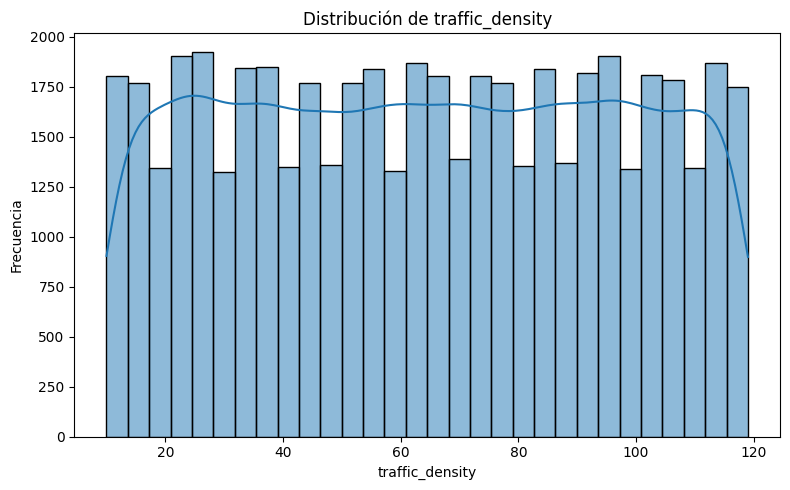

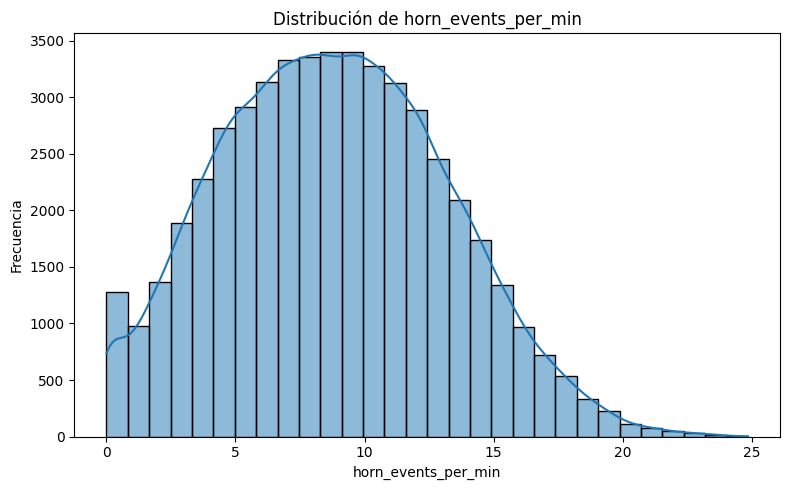

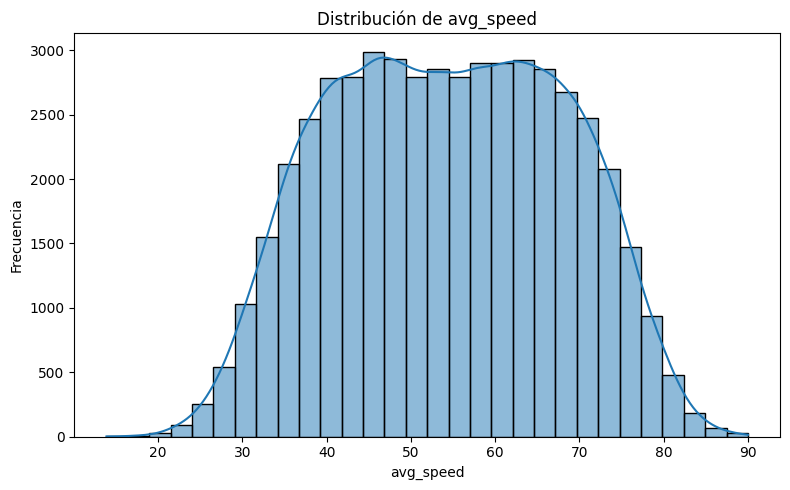

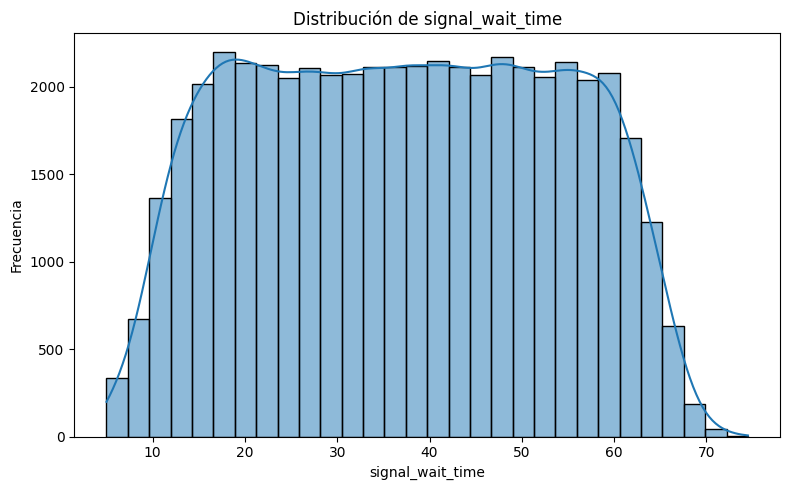

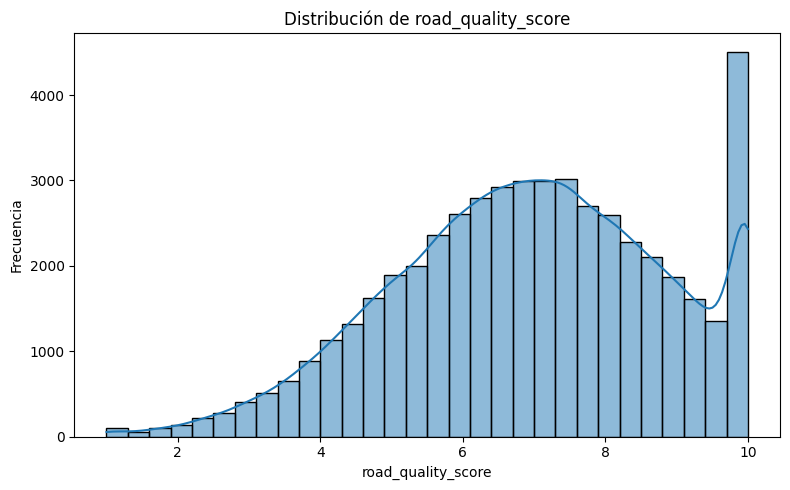

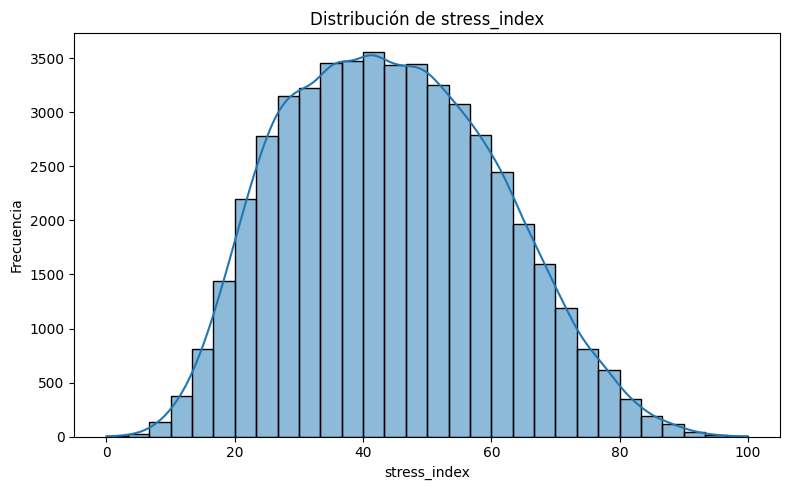

In [ ]:
for col in num_cols:
    plt.figure(figsize=(8,5))
    sns.histplot(data=df, x=col, bins=30, kde=True)
    plt.title(f"Distribución de {col}")
    plt.xlabel(col)
    plt.ylabel("Frecuencia")
    plt.tight_layout()
    plt.show()

**Traffic_density:** esta presenta una distribución bastante homogenea a lo largo del todo el rango, no hay intervalos dominantes lo cual nos dice que es muy equilibrado los distintos niveles de congestión del trafico.

**Horn_events_per_min:** Esta variable presenta una distribución que se concentra en la parte derecha, con una mayor concentración en los valores bajos e intermedios y ya para los valores mas altos se hace poco frecuente.

**Avg_speed:** la velocidad promedio presenta una mayor concentración en los valores medios y ya para velocidades extremas o muy bajas se hace poco frecuente.

**Signal_wait_time:** esta es la variable del tiempo de espera en los semáforos aqui se presenta una distribución muy homogenea pero en los mayores y menores valores tienen menor frecuencia.

**Road_quality_score:** la distribucuón de la variable de la calidad de la vía se concentra en valores altos lo que indica que la calidad de la vía era alta/media.

**stress_index:** esta distribución se centra en los valores intermedios y menor frecuencia en los extremos con una mayor concentración en los valores 40-50


Para las variables categorícas use la función "countplot" para conocer la frecuencia de estas columnas.

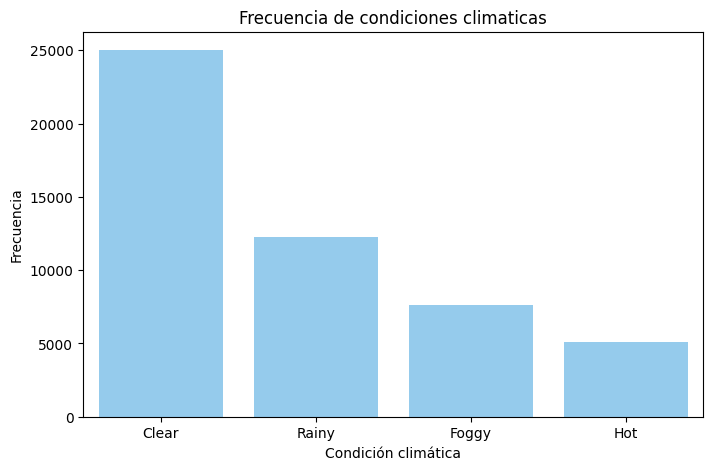

In [ ]:
#Frecuencia con la que aparecen las categorías de Clear, Rainy, Foggy y Hot
plt.figure(figsize=(8,5))
sns.countplot(data = df, x="weather_condition", order= df["weather_condition"].value_counts().index, color="lightskyblue")
plt.title("Frecuencia de condiciones climaticas")
plt.xlabel("Condición climática")
plt.ylabel("Frecuencia")
plt.show()

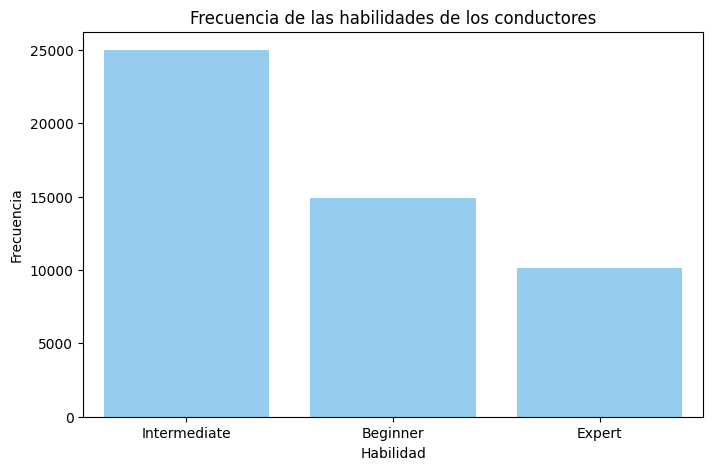

In [ ]:
plt.figure(figsize=(8,5))
sns.countplot(data = df, x="driver_experience_level", color="lightskyblue")
plt.title("Frecuencia de las habilidades de los conductores")
plt.xlabel("Habilidad")
plt.ylabel("Frecuencia")
plt.show()

Boxplots los graficare para observar si mis datos estas sesgados o bien si tengo outliers, sin embargo si encuentro outliers trabajare con ellos y no los eliminare debido a que son valores "extremos" pero no son valores imposibles.


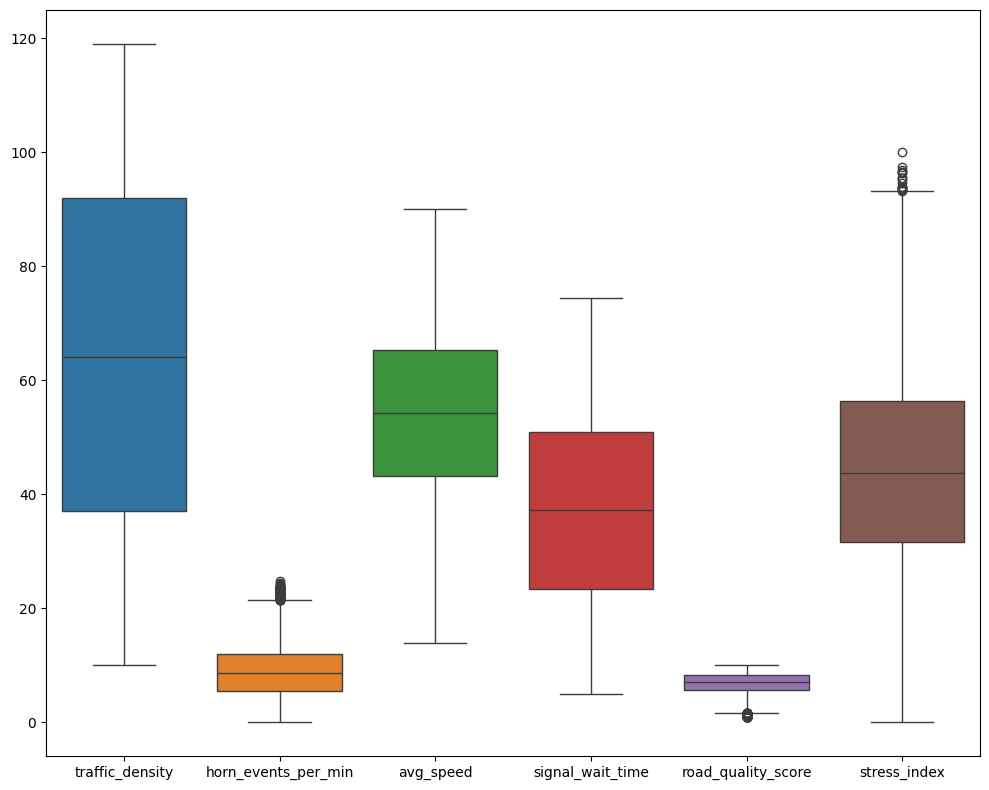

In [ ]:
#Boxplots con el fin de detectar valores que esten
plt.figure(figsize=(10,8))
boxplot=sns.boxplot(data=df)
plt.tight_layout()



**Traffic_density:** tiene una dispersión amplia, su mediana se encuentra mas o menos por 65 y no se aprecian muchos outliers

**Horn_events_per_min:** la mayoría de los datos estan en valores bajos e intermedios aparecen varios outliers sobre el limite superior y la mediana esta como por 10 mas o menos

**Avg_speed:** la variabilidad es "normal", con una media aproximadamente por 54 parece ser una distribución mas o menos estable es decir, la caja esta mas o menos a la mitad de los bigotes.

**Signal_wait_time:** la dispersión es amplia considerando el tamaño de los bigotes, la mediana es de mas o menos 37.

**Road_quality_score:** el rango de los bigotes es corto, la caja también es un poco pequeña, la mediana es mas o menos de 7.

**Stress_index:** la dispersión es bastante moderada considerando el tamaño de los bigotes la mediana es de mas o menos 43 y aparecen varios outliers.

#Análisis de la variable stress_index

Debido a que queremos estudiar el estres del trafico la columna mas importante es stress_index

Por lo tanto analizaremos las siguientes preguntas:

¿qué variables aumentan el stress_index?

¿qué variables lo reducen?

¿cómo cambia según el clima?

¿cómo cambia según la experiencia del conductor?

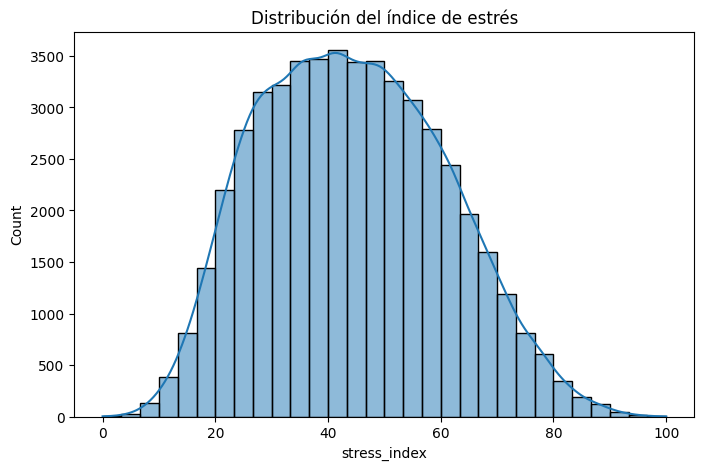

In [ ]:
plt.figure(figsize=(8,5))
sns.histplot(df["stress_index"], bins=30, kde=True)
plt.title("Distribución del índice de estrés")
plt.show()

###¿Qué variables aumentan el estres?

In [ ]:
corr_stress = df.corr(numeric_only=True)["stress_index"].sort_values(ascending=False)
print(corr_stress)

stress_index           1.000000
traffic_density        0.852951
signal_wait_time       0.845248
horn_events_per_min    0.763327
road_quality_score    -0.249190
avg_speed             -0.811367
Name: stress_index, dtype: float64


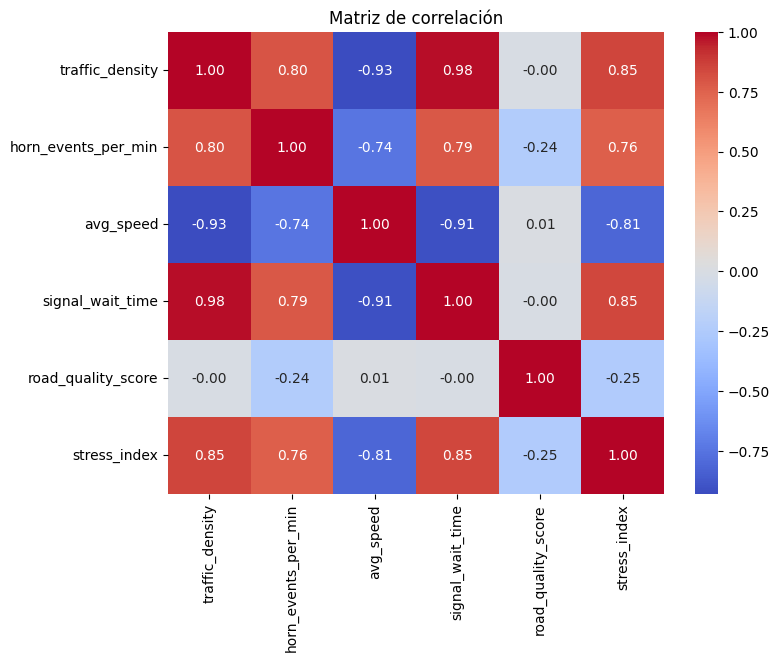

In [ ]:
#correlaciones
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Matriz de correlación")
plt.show()

más densidad de tráfico $\rightarrow$ más estrés

más tiempo esperando semáforo $\rightarrow$ más estrés

más bocinas por minuto $\rightarrow$ más estrés

mayor velocidad promedio $\rightarrow$ menos estrés

mejor calidad de la vía $\rightarrow$ menos estrés

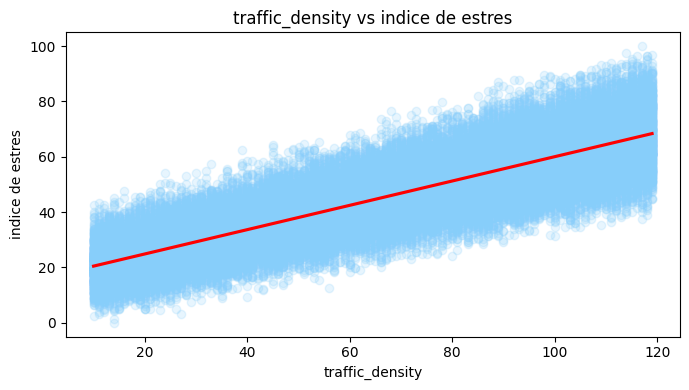

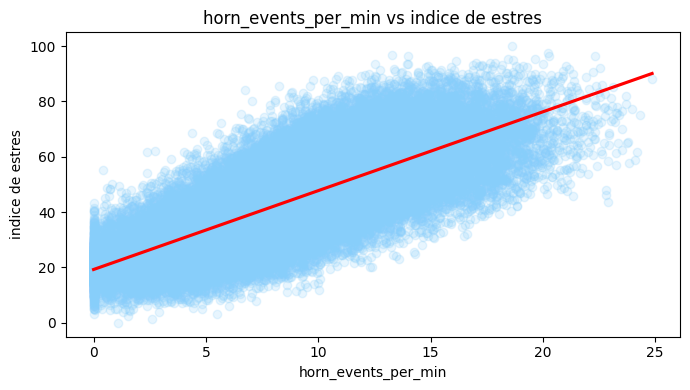

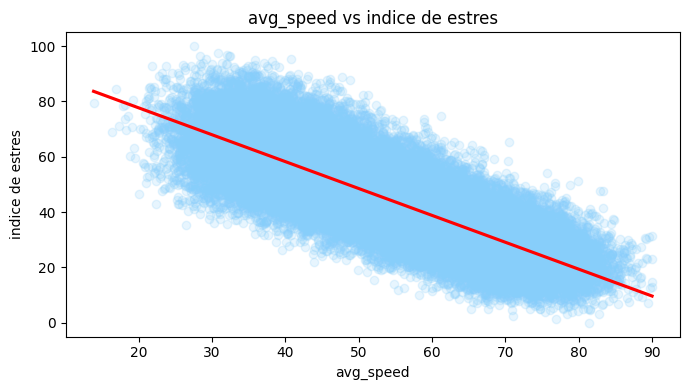

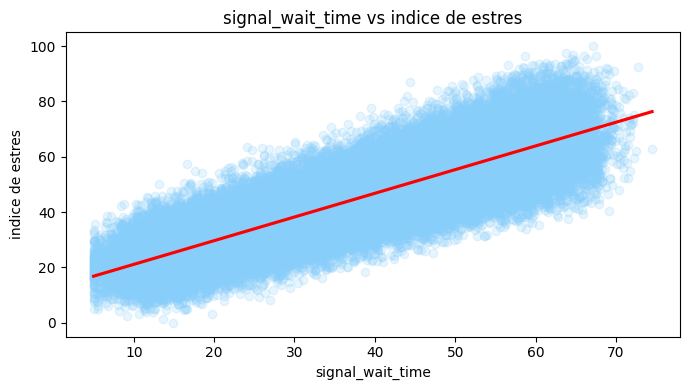

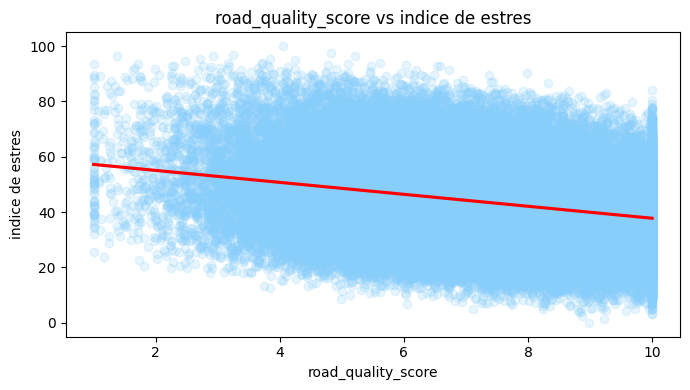

In [ ]:
vars_exp = ["traffic_density","horn_events_per_min","avg_speed","signal_wait_time","road_quality_score"]

for col in vars_exp:
  plt.figure(figsize=(7,4))
  sns.regplot(data=df, x=col, y="stress_index", color="lightskyblue", scatter_kws={"alpha":0.2}, line_kws={"color":"red"})
  plt.title(f"{col} vs indice de estres")
  plt.xlabel(col)
  plt.ylabel("indice de estres")
  plt.tight_layout()
  plt.show()

Las variables que aumentan el indice de estrés son la densidad del tráfico, los eventos de bocinas por minuto y el tiempo de espera en el semáforo ya que estos presentan una relación positiva con el estrés.

Las variables que disminuyen el estrés son la velocidad promedio y la calidad de la vía muestran una relación negativa con el indice de estrés.

###¿Cómo cambia según el clima?


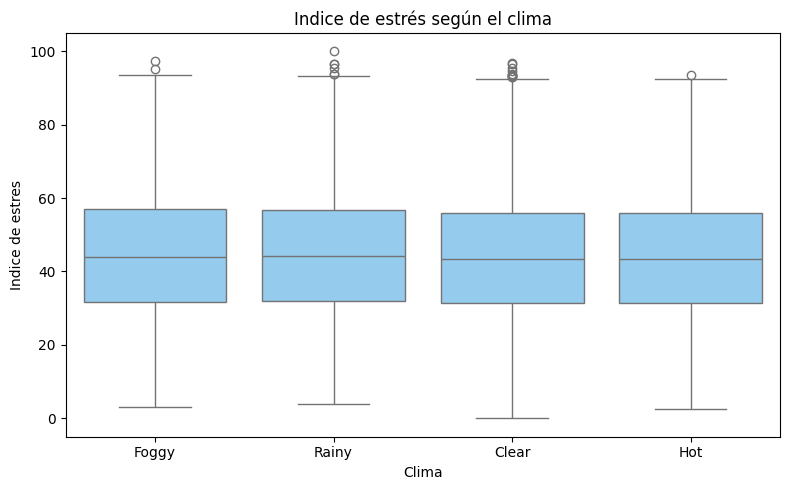

In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(x="weather_condition", y="stress_index", data= df, color="lightskyblue")
plt.title("Indice de estrés según el clima")
plt.xlabel("Clima")
plt.ylabel("Indice de estres")
plt.tight_layout()
plt.show()

In [ ]:
resumen_clima = df.groupby("weather_condition")["stress_index"].agg(["mean", "median", "std", "min", "max"])
print(resumen_clima)

                        mean  median        std   min     max
weather_condition                                            
Clear              44.151562  43.455  16.280372  0.00   96.86
Foggy              44.879062  44.000  16.586383  3.22   97.46
Hot                44.252354  43.355  16.276568  2.47   93.57
Rainy              44.679565  44.100  16.371892  3.94  100.00


Al comparar el índice de estrés según la condición climática, se observa que las diferencias entre categorías climáticas no son muy marcadas. Las distribuciones son bastantes similares, por lo que el clima parecec tener un efecto menos fuerte que otras variables numéricas.

###¿Cómo cambia según la experiencia del conductor?

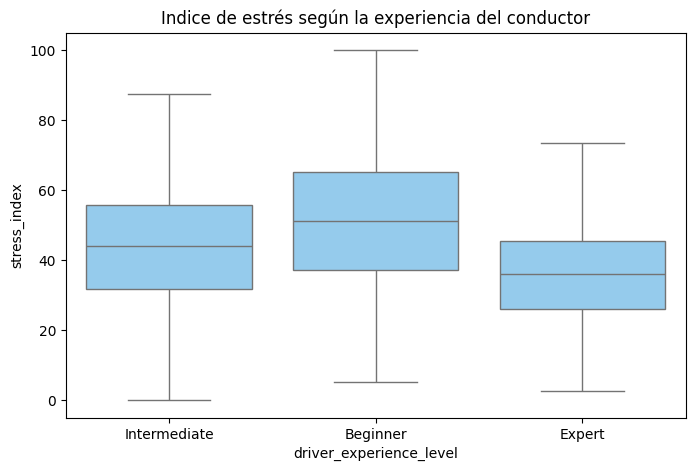

In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(x="driver_experience_level",y="stress_index",data=df, color="lightskyblue")
plt.title("Indice de estrés según la experiencia del conductor")
plt.show()

In [ ]:
#promedio del estres por experiencia
print(df.groupby("driver_experience_level")["stress_index"].agg(["mean", "median", "std", "count"]))

                              mean  median        std  count
driver_experience_level                                     
Beginner                 51.165522  51.090  17.748213  14872
Expert                   35.946368  35.935  12.413920  10148
Intermediate             43.810990  43.890  15.113717  24980


El análisis por nivel de experiencia muestra diferencias más claras. Los conductores principiantes presentan mayores niveles de estrés, los intermedios se ubican en una posición media y los expertos muestran menores niveles de estrés. esto sugiere que la experiencia del conductor es un factor importante en la variación del índice de estrés.

driver_experience_level   Beginner     Expert  Intermediate
weather_condition                                          
Clear                    51.152671  35.709072     43.414071
Foggy                    51.654077  36.221033     44.370715
Hot                      50.794903  35.972635     44.078203
Rainy                    51.033063  36.264614     44.153946


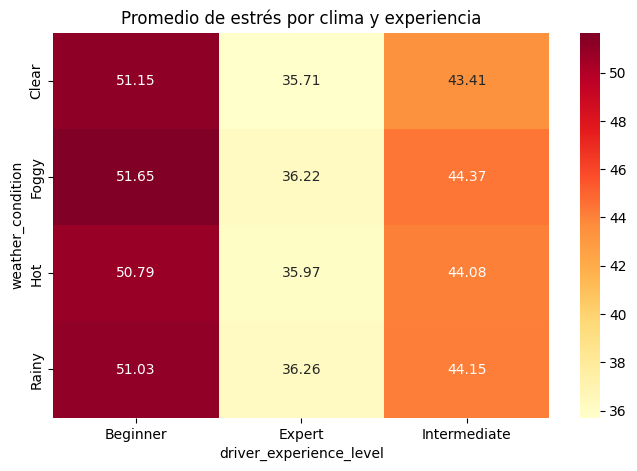

In [ ]:
tabla = df.pivot_table(values="stress_index",
                       index="weather_condition",
                       columns="driver_experience_level",
                       aggfunc="mean")

print(tabla)

plt.figure(figsize=(8,5))
sns.heatmap(tabla, annot=True, cmap="YlOrRd", fmt=".2f")
plt.title("Promedio de estrés por clima y experiencia")
plt.show()

El mapa de calor del promedio del indice de estrés según el clima y experiencia del conductor, muestra que la experiencia del conductor es el factor que mas diferencia los niveles de estrés

Finalmente en este análisis se encontro que variables como la **densidad del tráfico, el número de bocinas por minuto y el tiempo de espera en los semáforos** tienen una relación positiva con el estrés, lo que indica que condiciones de congestión y ruido incrementan significativamente la tensión del conductor. Por el contrario, una mayor **velocidad promedio y una mejor calidad de la vía** se asocian con menores niveles de estrés, sugiriendo que un flujo vehicular más fluido y condiciones adecuadas de infraestructura contribuyen a una conducción más tranquila.

Además, **el nivel de experiencia del conductor** juega un papel relevante, ya que los conductores principiantes presentan mayores niveles de estrés en comparación con los más experimentados. En cambio, las **condiciones climáticas** no muestran un impacto significativo, lo que sugiere que su influencia es menor frente a factores operativos del tráfico.